# CSIRO Image2Biomass · Assignment 1: EDA and baselines

**CENG313 · Group 42**

We predict five dry biomass weights (in grams) from a top-view pasture image.   This notebook follows the course structure: problem definition, data overview, exploratory data analysis, preprocessing, baseline models, Kaggle submission and conclusions.

**How to run.** Open the notebook in Colab, add your Kaggle API token to the 🔑 **Secrets** panel as `KAGGLE_API_TOKEN` (with notebook access enabled) and run the cells in order.   Reusable code lives in `src/data.py`, `src/models.py` and `src/utils.py` of the repository. [Kaggle data description](https://www.kaggle.com/competitions/csiro-biomass/data)

## 0. Setup

In [1]:
# Clone the project repository so the notebook can import the code in src/.
import os

if not os.path.isdir("src"):
    if not os.path.isdir("GROUP42_CENG313"):
        !git clone https://github.com/yavuzhan-kilic/GROUP42_CENG313.git
    %cd GROUP42_CENG313

Cloning into 'GROUP42_CENG313'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 39 (delta 15), reused 36 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 2.63 MiB | 3.64 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/GROUP42_CENG313


In [2]:
import subprocess
import sys
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import (biomass_differences, image_features, image_sizes,
                      image_table, load_image, metadata_table)
from src.models import (cross_validate, group_folds, kaggle_r2,
                        mean_predictions, rgb_ridge_predictions, split_images)

# Use CSIRO_DATA_DIR if it is set, otherwise the default Colab location.
data_dir = Path(os.environ.get("CSIRO_DATA_DIR", "/content/csiro_data"))

# Download and extract the competition data only if it is not there yet.
if not (data_dir / "train.csv").is_file():
    zip_path = data_dir.parent / "csiro-biomass.zip"
    if not zip_path.is_file():
        from google.colab import userdata

        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
        subprocess.run(["kaggle", "competitions", "download", "csiro-biomass",
                        "-p", str(zip_path.parent)], check=True)
    with ZipFile(zip_path) as archive:
        archive.extractall(data_dir)

print("Data directory:", data_dir)
print("Files:", sorted(file.name for file in data_dir.iterdir()))

Data directory: /content/csiro_data
Files: ['sample_submission.csv', 'test', 'test.csv', 'train', 'train.csv']


## 1. Problem Definition

**Task.** Each image shows a 70 cm × 30 cm quadrat of pasture seen from above. From the image alone we predict five dry biomass weights in grams. This is a regression problem with five outputs.

**Targets.**

| Target | Meaning |
|---|---|
| `Dry_Green_g` | green vegetation other than clover |
| `Dry_Dead_g` | dead (senescent) material |
| `Dry_Clover_g` | clover |
| `GDM_g` | green dry matter = green + clover |
| `Dry_Total_g` | total biomass = GDM + dead |

Only the first three are independent: GDM and total are sums of them.

**Input at test time.** Only the image. The metadata in `train.csv` (date, state, species, NDVI, height) is not in `test.csv` (section 3.4).

**Metric.** Kaggle uses a globally weighted R² computed over all (image, target) rows together, in grams and without a log transform:

$$R^2_w = 1 - \frac{\sum_j w_j (y_j - \hat{y}_j)^2}{\sum_j w_j (y_j - \bar{y}_w)^2}, \qquad \bar{y}_w = \frac{\sum_j w_j y_j}{\sum_j w_j}$$

The weight $w_j$ of a row depends on its target: 0.5 for `Dry_Total_g`, 0.2 for `GDM_g` and 0.1 for the other three. We implement it as `kaggle_r2` in `src/models.py`.

**How to read it.** 1 means perfect predictions, 0 means no better than predicting the single weighted mean $\bar{y}_w$ for every row, and negative values are worse than that. Two consequences:

- The reference is one mean shared by all five targets, so a model that predicts each target's own mean already scores above 0 (section 5.2).
- Total biomass carries half of the weight and errors are squared in grams, so large errors on high-biomass images cost the most.

## 2. Data Overview

`train.csv` has one row per **image and target pair**. We first look at its size, columns, types, summary statistics and missing values.

In [3]:
data = pd.read_csv(data_dir / "train.csv")

print("Rows and columns:", data.shape)
display(data.head(10))
display(pd.DataFrame({"Type": data.dtypes, "Unique values": data.nunique()}))

Rows and columns: (1785, 9)


,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target
0,ID1011485656__Dry_Clover_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000
1,ID1011485656__Dry_Dead_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984
2,ID1011485656__Dry_Green_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751
3,ID1011485656__Dry_Total_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735
4,ID1011485656__GDM_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750
5,ID1012260530__Dry_Clover_g,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Clover_g,0.0000
6,ID1012260530__Dry_Dead_g,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Dead_g,0.0000
7,ID1012260530__Dry_Green_g,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Green_g,7.6000
8,ID1012260530__Dry_Total_g,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Total_g,7.6000
9,ID1012260530__GDM_g,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,GDM_g,7.6000


,Type,Unique values
sample_id,object,1785
image_path,object,357
Sampling_Date,object,28
State,object,4
Species,object,15
Pre_GSHH_NDVI,float64,65
Height_Ave_cm,float64,81
target_name,object,5
target,float64,1328


In [4]:
# Summary statistics for every column (numbers: mean and spread, text: unique values and most frequent value).
display(data.describe(include="all").T)

# Missing values per column in the raw table.
display(data.isna().sum().rename("Missing values").to_frame())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,1785,1785,ID1011485656__Dry_Clover_g,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_path,1785,357,train/ID1011485656.jpg,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sampling_Date,1785,28,2015/6/26,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1785,4,Tas,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Species,1785,15,Ryegrass_Clover,490,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pre_GSHH_NDVI,1785.0,NaN,NaN,NaN,0.657423,0.151972,0.16,0.56,0.69,0.77,0.91
Height_Ave_cm,1785.0,NaN,NaN,NaN,7.595985,10.273725,1.0,3.0,4.0,7.0,70.0
target_name,1785,5,Dry_Clover_g,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,1785.0,NaN,NaN,NaN,24.782295,25.823738,0.0,4.8182,18.2,35.9406,185.7


,Missing values
sample_id,0
image_path,0
Sampling_Date,0
State,0
Species,0
Pre_GSHH_NDVI,0
Height_Ave_cm,0
target_name,0
target,0


**Findings.**

- All 1,785 rows are complete: no column has missing values.
- The `NaN` entries in the summary are expected: text columns have no mean or quantiles, and numeric columns have no `unique`, `top` or `freq`.
- Every image appears in exactly five rows (`freq` is 5 for `image_path` and 357 for each `target_name`).
- `Height_Ave_cm` is very skewed: 75% of the rows are at or below 7 cm, but the maximum is 70 cm. Height is not available at test time, so we use it only for exploration and not as a feature.
- The `target` column mixes five different variables, so its summary (mean 24.8 g) is not meaningful on its own. Section 2.1 splits it into one column per target.

**Variable types** (course week 3–4):

| Column | Type | Note |
|---|---|---|
| `sample_id`, `image_path` | identifier | not features |
| `State`, `Species` | categorical, nominal | no order between categories |
| `Sampling_Date` | numeric, interval scale | differences are meaningful, ratios are not |
| `Pre_GSHH_NDVI` | numeric, continuous index | vegetation index measured before cutting |
| `Height_Ave_cm` | numeric, ratio scale | true zero |
| `target` (five biomass weights) | numeric, ratio scale | 0 g means no material |

The five targets are `Dry_Green_g`, `Dry_Dead_g`, `Dry_Clover_g`, `GDM_g` (green dry matter = green + clover) and `Dry_Total_g` (GDM + dead).

### 2.1 Tidy Data

The raw table is **not tidy**: five different variables are stored in one `target` column and named by `target_name`. We reshape it so that each row is one observation (an image) and each column is one variable. Image metadata goes into a second table with the same index.

In [5]:
# One row per image, one column per target. pivot() fails on duplicate pairs.
images = image_table(data)

# One row per image with the non-target columns (date, state, species, NDVI, height).
metadata = metadata_table(data)
metadata["Sampling_Date"] = pd.to_datetime(metadata["Sampling_Date"])

print("Raw rows:", len(data))
print("Unique images:", len(images))
print("Rows per image:", data.groupby("image_path").size().unique())

display(images.head())
display(metadata.head())

Raw rows: 1785
Unique images: 357
Rows per image: [5]


target_name,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g
image_path,,,,,
train/ID1011485656.jpg,0.0000,31.9984,16.2751,48.2735,16.2750
train/ID1012260530.jpg,0.0000,0.0000,7.6000,7.6000,7.6000
train/ID1025234388.jpg,6.0500,0.0000,0.0000,6.0500,6.0500
train/ID1028611175.jpg,0.0000,30.9703,24.2376,55.2079,24.2376
train/ID1035947949.jpg,0.4343,23.2239,10.5261,34.1844,10.9605


,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm
image_path,,,,,
train/ID1011485656.jpg,2015-09-04,Tas,Ryegrass_Clover,0.62,4.6667
train/ID1012260530.jpg,2015-04-01,NSW,Lucerne,0.55,16.0000
train/ID1025234388.jpg,2015-09-01,WA,SubcloverDalkeith,0.38,1.0000
train/ID1028611175.jpg,2015-05-18,Tas,Ryegrass,0.66,5.0000
train/ID1035947949.jpg,2015-09-11,Tas,Ryegrass,0.54,3.5000


### 2.2 Trust: Data Quality

Before analysing the values we ask how far we can trust them. We look for the problem types from the lecture: duplicates, missing values, erroneous (impossible) values and inconsistent values.

In [6]:
print("Exact duplicate rows:", data.duplicated().sum())
print("Duplicate sample ids:", data["sample_id"].duplicated().sum())

# Missing and negative (impossible) measurements per target.
display(pd.DataFrame({
    "Missing": images.isna().sum(),
    "Negative": images.lt(0).sum(),
}))

# Missing metadata values per column.
display(metadata.isna().sum().rename("Missing metadata values").to_frame())

Exact duplicate rows: 0
Duplicate sample ids: 0


,Missing,Negative
target_name,,
Dry_Clover_g,0,0
Dry_Dead_g,0,0
Dry_Green_g,0,0
Dry_Total_g,0,0
GDM_g,0,0


,Missing metadata values
Sampling_Date,0
State,0
Species,0
Pre_GSHH_NDVI,0
Height_Ave_cm,0


In [7]:
# The labels should satisfy: green + clover = GDM, and GDM + dead = total.
differences = biomass_differences(images)
display(differences.max().round(4).rename("Largest difference (g)").to_frame())

# Review the images where a sum is off by more than 0.1 g.
flagged = differences[differences.gt(0.1).any(axis=1)]
print("Images with a difference above 0.1 g:", len(flagged))
display(images.loc[flagged.index].join(flagged.round(4)))

,Largest difference (g)
Green + clover difference (g),0.0001
Total biomass difference (g),0.3088


Images with a difference above 0.1 g: 1


,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,Green + clover difference (g),Total biomass difference (g)
image_path,,,,,,,
train/ID2014192906.jpg,0.5,7.0,3.0,10.1912,3.5,0.0,0.3088


In [8]:
# Open every image: compute mean RGB values and list missing or unreadable files.
rgb, missing_images, unreadable_images = image_features(data_dir, images.index)

print("Images checked:", len(images))
print("Missing image files:", len(missing_images))
print("Unreadable image files:", len(unreadable_images))

# Image dimensions.
display(image_sizes(data_dir, images.index).value_counts().rename("Images").to_frame())

Images checked: 357
Missing image files: 0
Unreadable image files: 0


,,Images
Width,Height,
2000,1000,357


**Findings.**

- The 1,785 raw rows become 357 unique images with exactly five rows each. There are no duplicate rows, no missing or negative targets and no missing or unreadable image files.
- The metadata has no missing values, and all 357 images have the same size (2000 × 1000 pixels).
- One image has an **inconsistent value** (attribute noise): for `ID2014192906.jpg`, GDM + dead = 10.5 g but the recorded total is 10.1912 g, a gap of 0.3088 g. We keep the original values and report the discrepancy, because we cannot tell which of the numbers is wrong.
- We did not remove or impute any value, so the cleaned table contains the original measurements.

  ## 3. Exploratory Data Analysis

  ### 3.1 Distributions

How much do the targets vary? Each plot is paired with summary statistics, because a plot alone can mislead.

,count,mean,std,min,25%,50%,75%,max,skew
target_name,,,,,,,,,
Dry_Clover_g,357.0,6.65,12.12,0.00,0.00,1.42,7.24,71.79,2.84
Dry_Dead_g,357.0,12.04,12.40,0.00,3.20,7.98,17.64,83.84,1.76
Dry_Green_g,357.0,26.62,25.40,0.00,8.80,20.80,35.08,157.98,1.75
Dry_Total_g,357.0,45.32,27.98,1.04,25.27,40.30,57.88,185.70,1.43
GDM_g,357.0,33.27,24.94,1.04,16.03,27.11,43.68,157.98,1.56


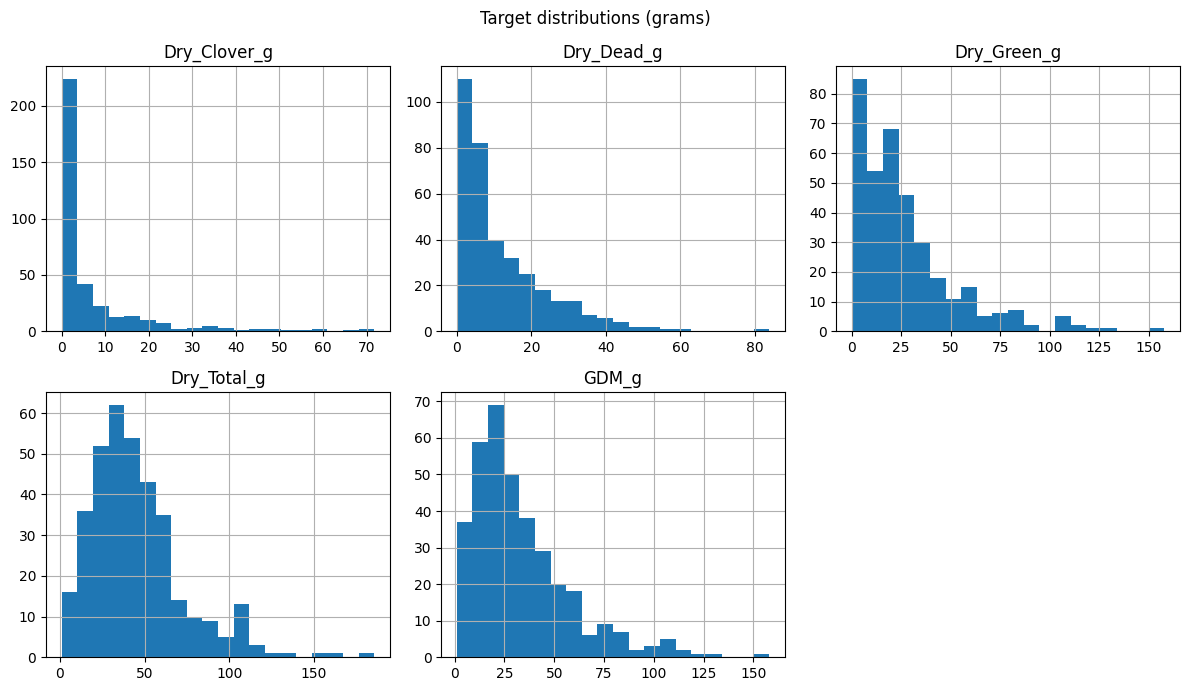

In [9]:
# Summary statistics plus skewness (0 = symmetric, positive = long right tail).
summary = images.describe().T
summary["skew"] = images.skew()
display(summary.round(2))

images.hist(bins=20, figsize=(12, 7), layout=(2, 3))
plt.suptitle("Target distributions (grams)")
plt.tight_layout()
plt.show()

In [10]:
# Exact zeros per target.
zeros = images.eq(0).sum()
display(pd.DataFrame({"Images with 0 g": zeros,
                      "Share (%)": (100 * zeros / len(images)).round(1)}))

,Images with 0 g,Share (%)
target_name,,
Dry_Clover_g,135,37.8
Dry_Dead_g,40,11.2
Dry_Green_g,18,5.0
Dry_Total_g,0,0.0
GDM_g,0,0.0


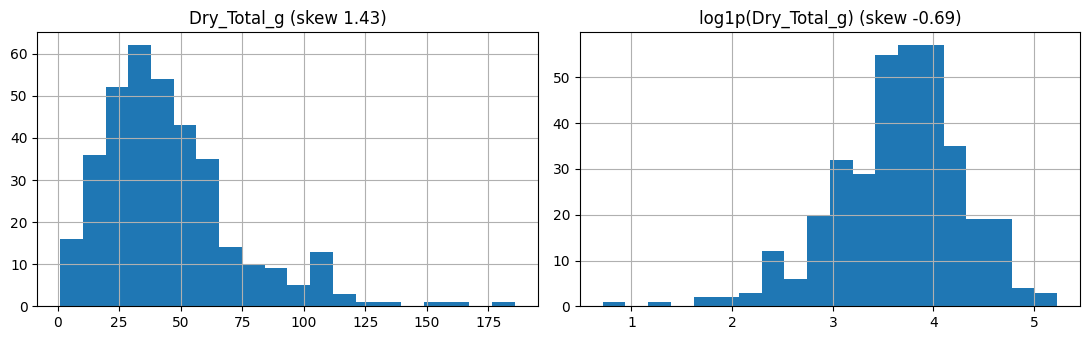

In [11]:
# A log transform compresses the long right tail. log1p(x) = log(1 + x) is defined at 0.
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
images["Dry_Total_g"].hist(bins=20, ax=axes[0])
axes[0].set_title(f"Dry_Total_g (skew {images['Dry_Total_g'].skew():.2f})")
np.log1p(images["Dry_Total_g"]).hist(bins=20, ax=axes[1])
axes[1].set_title(f"log1p(Dry_Total_g) (skew {np.log1p(images['Dry_Total_g']).skew():.2f})")
plt.tight_layout()
plt.show()

**Findings.**

- Clover is exactly 0 g in 135 of 357 images (37.8%), dead material in 40 (11.2%) and green in 18 (5.0%). We treat these zeros as valid measurements (a paddock without clover), not as missing values.
- All five targets are right-skewed. Clover has the highest skew (2.84), followed by dead (1.76), green (1.75), GDM (1.56) and total (1.43).
- Total biomass has a median of 40.3 g. Half of the images lie between 25.3 g and 57.9 g, while the maximum is 185.7 g.
- The log transform shortens the right tail of total biomass: the skew changes from 1.43 to −0.69. The result is not symmetric, it is now slightly left-skewed, but the extreme values no longer dominate. Training on a log scale is an option for Assignment 2.

### 3.2 Extremes (Outliers)

Which images have the lowest and highest total biomass, and do the extreme labels look plausible in the image?

,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm
image_path,,,,,,,,,,
train/ID1963715583.jpg,0.34,0.00,0.70,1.04,1.04,2015-07-08,WA,Clover,0.16,1.0000
train/ID1889150649.jpg,2.48,0.00,0.00,2.48,2.48,2015-09-01,WA,SubcloverLosa,0.32,1.0000
train/ID956512130.jpg,0.00,1.90,2.40,4.30,2.40,2015-11-09,Tas,Ryegrass_Clover,0.19,1.0000
train/ID1139866256.jpg,0.00,83.84,74.06,157.90,74.06,2015-05-07,NSW,Fescue,0.66,13.0000
train/ID746335827.jpg,0.00,53.26,112.84,166.10,112.84,2015-10-06,NSW,Fescue,0.75,24.3333
train/ID384648061.jpg,0.00,27.72,157.98,185.70,157.98,2015-10-06,NSW,Fescue,0.85,14.6667


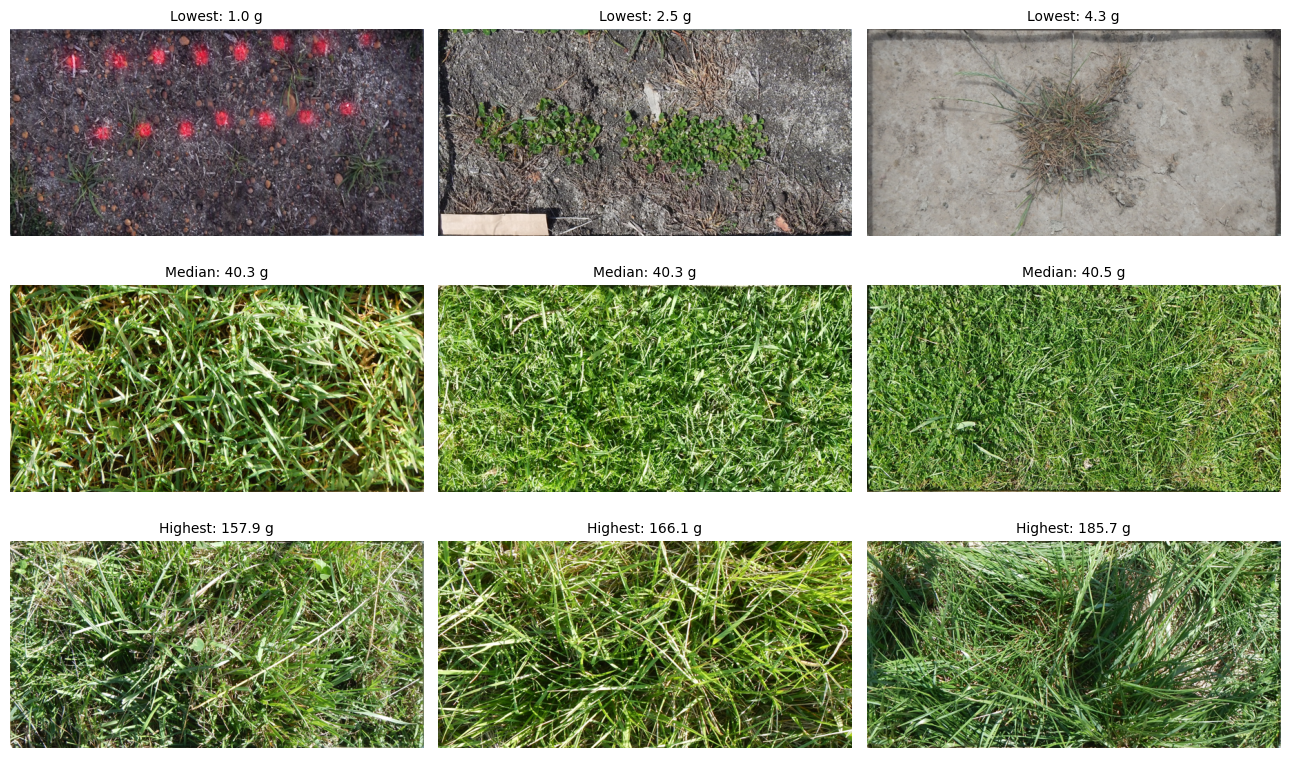

In [12]:
ranked = images["Dry_Total_g"].sort_values()
middle = len(ranked) // 2
selection = {
    "Lowest": ranked.index[:3],
    "Median": ranked.index[middle - 1:middle + 2],
    "Highest": ranked.index[-3:],
}

display(images.round(2).join(metadata)
        .loc[list(selection["Lowest"]) + list(selection["Highest"])])

figure, axes = plt.subplots(3, 3, figsize=(13, 8))
for row, (label, paths) in zip(axes, selection.items()):
    for axis, path in zip(row, paths):
        axis.imshow(load_image(data_dir, path))
        axis.set_title(f"{label}: {images.loc[path, 'Dry_Total_g']:.1f} g", fontsize=10)
        axis.axis("off")
plt.tight_layout()
plt.show()

**Findings.**

- The three lowest images (1.0, 2.5 and 4.3 g) show almost bare soil with a few small plants, so the low labels match the images.
- The three highest images (157.9, 166.1 and 185.7 g) are all Fescue from NSW with an average height of 13 to 24 cm. They show tall, dense grass, so these values look like real measurements and not like errors. We keep them.
- The median images (about 40 g) and the highest images look similarly green from above. What separates them is the height and density of the grass, not its colour. A model that only uses colour will therefore struggle with high biomass.

### 3.3 Correlation (Relationships With the Targets)

First between the five targets, then between the image metadata and the targets.

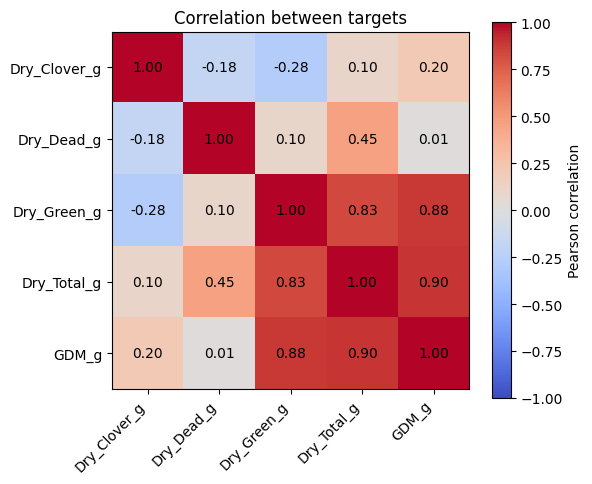

In [13]:
correlation = images.corr()

figure, axis = plt.subplots(figsize=(6, 5))
heatmap = axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axis.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right")
axis.set_yticks(range(len(correlation)), correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        axis.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
figure.colorbar(heatmap, label="Pearson correlation")
axis.set_title("Correlation between targets")
plt.tight_layout()
plt.show()

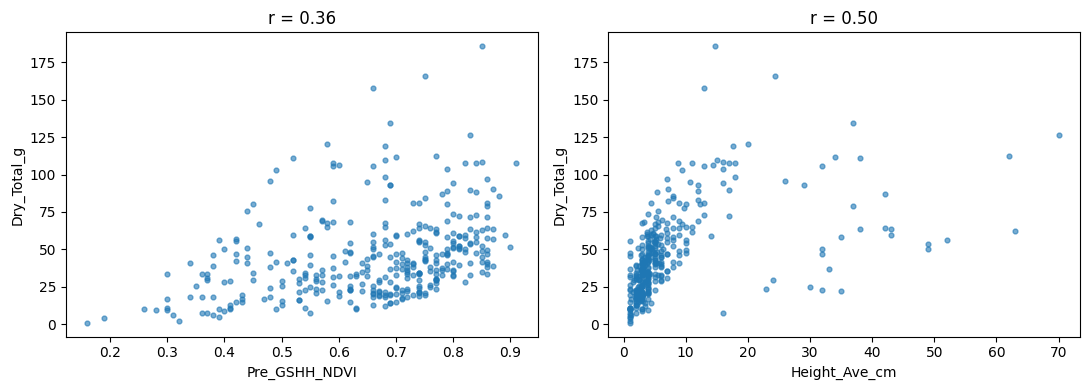

,Pre_GSHH_NDVI,Height_Ave_cm,Red,Green,Blue
target_name,,,,,
Dry_Clover_g,0.22,-0.16,-0.24,-0.01,-0.24
Dry_Dead_g,-0.12,-0.05,0.20,-0.03,-0.02
Dry_Green_g,0.35,0.65,-0.15,0.19,-0.12
Dry_Total_g,0.36,0.50,-0.15,0.15,-0.23
GDM_g,0.47,0.58,-0.27,0.19,-0.24


In [14]:
# Numeric metadata against total biomass.
numeric_columns = ["Pre_GSHH_NDVI", "Height_Ave_cm"]

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, column in zip(axes, numeric_columns):
    r = metadata[column].corr(images["Dry_Total_g"])
    axis.scatter(metadata[column], images["Dry_Total_g"], s=12, alpha=0.6)
    axis.set_xlabel(column)
    axis.set_ylabel("Dry_Total_g")
    axis.set_title(f"r = {r:.2f}")
plt.tight_layout()
plt.show()

# Correlation of the numeric metadata and the mean colour values with every target.
display(pd.concat([metadata[numeric_columns], rgb], axis=1)
        .apply(lambda column: images.corrwith(column)).round(2))

,count,mean,median,std
State,,,,
Tas,138,36.8,32.8,20.7
Vic,112,42.7,40.2,20.9
NSW,75,70.9,63.3,35.6
WA,32,31.4,32.3,19.6


,count,mean,median,std
Species,,,,
Ryegrass_Clover,98,38.9,33.2,23.2
Ryegrass,62,37.5,35.2,17.8
Phalaris_Clover,42,51.4,49.3,21.6
Clover,41,33.0,28.1,20.1
Fescue,28,86.3,81.9,38.4
Lucerne,22,54.7,55.0,29.0
Phalaris_BarleyGrass_SilverGrass_SpearGrass_Clover_Capeweed,11,39.7,38.8,7.8
Fescue_CrumbWeed,10,46.6,43.1,17.3
WhiteClover,10,24.6,25.4,12.2


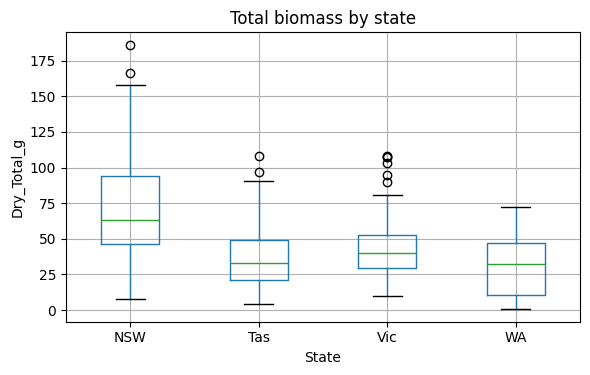

In [15]:
# Categorical metadata: number of images and total biomass per category.
table = images.join(metadata)

for column in ["State", "Species"]:
    display(table.groupby(column)["Dry_Total_g"]
            .agg(["count", "mean", "median", "std"]).round(1)
            .sort_values("count", ascending=False))

figure, axis = plt.subplots(figsize=(6, 4))
table.boxplot(column="Dry_Total_g", by="State", ax=axis)
axis.set_title("Total biomass by state")
axis.set_ylabel("Dry_Total_g")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Findings.**

- Green, GDM and total are strongly related: green and GDM 0.88, GDM and total 0.90, green and total 0.83. In many images there is little or no clover, so GDM is almost the same as green. Dead material is only moderately related to total (0.45), and clover is weakly negatively related to green (−0.28).
- Among the metadata, average height has the strongest relation with biomass: 0.65 with green and 0.50 with total. NDVI follows with 0.47 for GDM and 0.36 for total.
- The mean colour values are only weakly related to the targets (all correlations are between −0.27 and 0.20). The mean green value has a correlation of only 0.19 with green biomass.
- Biomass differs between states: the NSW mean is 70.9 g, while the other three states are between 31.4 g and 42.7 g. Fescue (86.3 g) and Phalaris (100.3 g, only 8 images) have the highest means among the species.

### 3.4 Data ≠ Truth: What is missing and who is not represented

A clean table is not automatically representative. We check what the test set contains and how the training images are spread over time and place.

In [16]:
# Which columns does the test set have? Columns missing here cannot be model inputs.
test = pd.read_csv(data_dir / "test.csv")
print("Test rows:", len(test), "| test images:", test["image_path"].nunique())
print("Test columns:", list(test.columns))
print("Train-only columns:", [column for column in data.columns if column not in test.columns])

Test rows: 5 | test images: 1
Test columns: ['sample_id', 'image_path', 'target_name']
Train-only columns: ['Sampling_Date', 'State', 'Species', 'Pre_GSHH_NDVI', 'Height_Ave_cm', 'target']


Sampling days: 28
From 2015-01-15 to 2015-11-10
Images per day: min 1 | median 11.0 | max 37


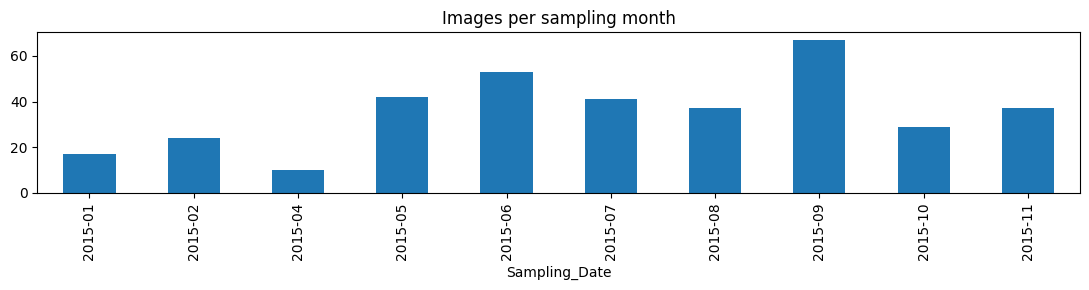

Species,Clover,Fescue,Fescue_CrumbWeed,Lucerne,Mixed,Phalaris,Phalaris_BarleyGrass_SilverGrass_SpearGrass_Clover_Capeweed,Phalaris_Clover,Phalaris_Clover_Ryegrass_Barleygrass_Bromegrass,Phalaris_Ryegrass_Clover,Ryegrass,Ryegrass_Clover,SubcloverDalkeith,SubcloverLosa,WhiteClover
State,,,,,,,,,,,,,,,
NSW,0,28,10,22,0,8,0,0,0,0,7,0,0,0,0
Tas,21,0,0,0,0,0,0,0,0,0,41,66,0,0,10
Vic,0,0,0,0,2,0,11,42,7,8,10,32,0,0,0
WA,20,0,0,0,0,0,0,0,0,0,4,0,3,5,0


In [17]:
# Sampling dates: how many days, and how many images per day and per month?
per_day = metadata["Sampling_Date"].value_counts().sort_index()
print("Sampling days:", len(per_day))
print("From", per_day.index.min().date(), "to", per_day.index.max().date())
print("Images per day: min", per_day.min(), "| median", per_day.median(), "| max", per_day.max())

per_month = metadata["Sampling_Date"].dt.to_period("M").value_counts().sort_index()
per_month.plot.bar(figsize=(11, 3), title="Images per sampling month")
plt.tight_layout()
plt.show()

display(pd.crosstab(metadata["State"], metadata["Species"]))

**Findings.**

- The test set has only `sample_id`, `image_path` and `target_name`. Sampling date, state, species, NDVI and height are not available at test time, so they cannot be model inputs. This matters because height was the most informative column in section 3.3. We use the metadata only to understand the data and to build the validation split.
- The downloaded test folder contains a single example image. The real test set is hidden.
- All images come from one year (15 January to 10 November 2015) and from 28 sampling days. There are no images from March or December, and April has only 10. A sampling day has between 1 and 37 images.
- The states are not equally represented: Tas 138, Vic 112, NSW 75 and WA 32 images. Several of the 15 species have fewer than 10 images (for example Mixed 2 and SubcloverDalkeith 3).
- Species and state are tied together: Fescue and Lucerne appear only in NSW. We cannot say whether the high biomass in NSW comes from the location or from the species.
- These are limitations of the data. We cannot fix them, but we take the batch structure into account when we validate the models.

## 4. Preprocessing

Every step is implemented in `src/` and applied in the same way in cross-validation and in the Kaggle submission.

| Step | What we did | Why |
|---|---|---|
| Reshaping | The long table (1,785 rows) becomes one row per image with five target columns (`image_table`). | One row per observation; every model predicts all five targets of an image. |
| Cleaning | No rows removed. The inconsistent image `ID2014192906` (0.31 g gap) is kept and reported. | We cannot tell which of its values is wrong, and the gap is small (0.3 g of about 10 g). |
| Missing values | No imputation: there are no missing targets, metadata or image files. Zeros are kept. | A 0 g clover value means there is no clover in the quadrat. It is a measurement, not a missing value. |
| Outliers | The highest images (up to 185.7 g) are kept. | Section 3.2 shows tall, dense grass, so they are real. The metric punishes large errors on them, so the model must learn them. |
| Encoding | `State` and `Species` are not encoded and not used as features. | They are not available at test time. If they were, we would need one-hot encoding because they are nominal. |
| Feature extraction | Each image is reduced to its mean red, green and blue value (`image_features`). | The simplest summary of an image, used for the baseline. |
| Scaling | `StandardScaler` before Ridge, fitted on the training images of each fold only. | Ridge penalises all coefficients equally, so features should be on the same scale. Fitting only on training data keeps the validation images unseen (no leakage). |
| Target transform | None for the baselines; targets stay in grams. | The metric is computed in grams. A log1p transform reduces skew (section 3.1) and is an option for Assignment 2. |
| Post-processing | Negative predictions are clipped to 0. | A weight cannot be negative. |

  ## 5. Baseline Models

  ### 5.1 Validation Strategy

Images taken on the same day in the same place look alike. With a random split, such near-copies land in both the training and the validation part, so the validation score can be too optimistic. We therefore compare two strategies:

1. **Random split**: 80% training, 20% validation, seed 42.
2. **Grouped 5-fold cross-validation**: all images from one sampling date stay in the same fold. Every image is used for validation exactly once, so the score is also less dependent on one lucky split.

In [18]:
train, validation = split_images(images, validation_ratio=0.20, seed=42)
print("Random split:", len(train), "training and", len(validation), "validation images")

shared_days = set(metadata.loc[train.index, "Sampling_Date"]) & set(metadata.loc[validation.index, "Sampling_Date"])
print("Sampling days that appear on both sides of the random split:", len(shared_days))

folds = group_folds(metadata["Sampling_Date"], n_splits=5)
display(pd.DataFrame({
    "Images": folds.value_counts().sort_index(),
    "Sampling days": metadata.groupby(folds)["Sampling_Date"].nunique(),
    "Mean Dry_Total_g": images.groupby(folds)["Dry_Total_g"].mean().round(1),
}).rename_axis("Fold"))

Random split: 286 training and 71 validation images
Sampling days that appear on both sides of the random split: 22


,Images,Sampling days,Mean Dry_Total_g
Fold,,,
0,74,5,45.6
1,68,5,51.4
2,74,6,46.4
3,73,6,40.2
4,68,6,43.3


### 5.2 Baselines

1. **Training mean.** Predicts the training mean of each target for every image. Any useful model must beat it.
2. **RGB + Ridge.** Reduces each image to three numbers (mean red, green and blue), standardises them and fits a Ridge regression to the five targets. Negative predictions are clipped to zero.

Scaling and model parameters are learned from the training images only. We report the **Kaggle weighted R²** (computed over all targets together; weights 0.5 for total, 0.2 for GDM, 0.1 for the others) and the **mean absolute error** in grams per target. [Kaggle evaluation](https://www.kaggle.com/competitions/csiro-biomass/overview/evaluation)

In [19]:
models = {
    "Training mean": mean_predictions,
    "RGB + Ridge": lambda train, index: rgb_ridge_predictions(rgb, train, index, alpha=1.0),
}

# Strategy 1: single random split.
random_split_r2 = pd.Series({name: kaggle_r2(validation, predict(train, validation.index))
                             for name, predict in models.items()})

# Strategy 2: grouped 5-fold cross-validation.
fold_scores, predictions = cross_validate(images, folds, models)
display(fold_scores.round(4))

results = pd.DataFrame({
    "Random split R²": random_split_r2,
    "Grouped CV R² (mean)": fold_scores.mean(),
    "Grouped CV R² (std)": fold_scores.std(),
    "Grouped CV R² (all images)": {name: kaggle_r2(images, predicted)
                                   for name, predicted in predictions.items()},
})
display(results.round(4))

,Training mean,RGB + Ridge
Fold,,
0,0.1821,0.1957
1,0.2265,0.3115
2,0.2033,0.4001
3,0.2505,0.2976
4,0.2792,0.1052


,Random split R²,Grouped CV R² (mean),Grouped CV R² (std),Grouped CV R² (all images)
Training mean,0.2096,0.2283,0.0382,0.2296
RGB + Ridge,0.2865,0.2620,0.1138,0.2758


,Training mean,RGB + Ridge
Target · MAE (g),,
Dry_Clover_g,8.20,8.32
Dry_Dead_g,9.62,8.93
Dry_Green_g,18.77,17.19
Dry_Total_g,20.98,20.76
GDM_g,18.86,16.76


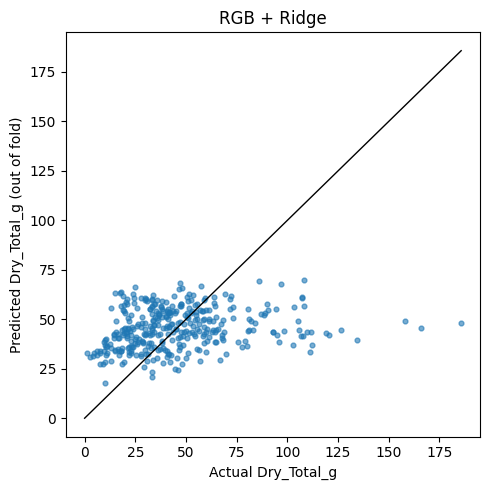

In [20]:
# Mean absolute error per target, from the out-of-fold predictions of the grouped CV.
mae = pd.DataFrame({name: (images - predicted).abs().mean()
                    for name, predicted in predictions.items()})
display(mae.round(2).rename_axis("Target · MAE (g)"))

# Predicted against actual total biomass for the Ridge baseline.
figure, axis = plt.subplots(figsize=(5, 5))
axis.scatter(images["Dry_Total_g"], predictions["RGB + Ridge"]["Dry_Total_g"], s=12, alpha=0.6)
limit = images["Dry_Total_g"].max()
axis.plot([0, limit], [0, limit], color="black", linewidth=1)
axis.set_xlabel("Actual Dry_Total_g")
axis.set_ylabel("Predicted Dry_Total_g (out of fold)")
axis.set_title("RGB + Ridge")
plt.tight_layout()
plt.show()

**Results.**

| Model | Random split R² | Grouped CV R² (mean ± std) |
|---|---|---|
| Training mean | 0.2096 | 0.2283 ± 0.0382 |
| RGB + Ridge | 0.2865 | 0.2620 ± 0.1138 |

- RGB + Ridge is only slightly better than the training mean. With grouped cross-validation its weighted R² is 0.2620, compared with 0.2283 for the mean.
- In the random split, 22 of the 28 sampling days appear in both the training and the validation part. With the grouped split the Ridge score drops from 0.2865 to 0.2620.
- The Ridge score changes a lot between folds, from 0.1052 to 0.4001. In fold 4 it is worse than the training mean (0.1052 against 0.2792). A score from a single split is therefore not reliable for 357 images, and we report the grouped cross-validation score as our baseline.
- Per target, Ridge lowers the MAE for green (18.77 g to 17.19 g), GDM (18.86 g to 16.76 g) and dead (9.62 g to 8.93 g). For total biomass there is almost no gain (20.98 g to 20.76 g), and for clover it is slightly worse (8.20 g to 8.32 g).
- In the scatter plot the Ridge predictions stay between about 25 g and 70 g. Images above 100 g are still predicted at around 45 g, so the model cannot recognise high biomass. This agrees with section 3.2: colour alone does not show how tall and dense the grass is.

## 6. Kaggle submission

The competition closed on 28 January 2026, so we made a **late submission**. It is a code competition: Kaggle reruns a notebook on the hidden test set with the internet disabled. We uploaded this repository as a private Kaggle dataset and ran the cell below in a Kaggle notebook (`group42-assignment1-baseline`, version 2). It fits RGB + Ridge on all 357 training images and writes `submission.csv` with `make_submission` from `src/utils.py`. The cell is shown as text because it only runs on Kaggle.

```python
import glob, os, sys
import pandas as pd

code_file = glob.glob("/kaggle/input/**/src/models.py", recursive=True)[0]
sys.path.insert(0, os.path.dirname(os.path.dirname(code_file)))
data_dir = os.path.dirname(glob.glob("/kaggle/input/**/test.csv", recursive=True)[0])

from src.data import image_features, image_table
from src.models import rgb_ridge_predictions
from src.utils import make_submission, save_submission

train = pd.read_csv(os.path.join(data_dir, "train.csv"))
test = pd.read_csv(os.path.join(data_dir, "test.csv"))
images = image_table(train)
test_paths = list(test["image_path"].unique())

rgb, missing, unreadable = image_features(data_dir, list(images.index) + test_paths)
assert not missing and not unreadable, (missing, unreadable)

predictions = rgb_ridge_predictions(rgb, images, test_paths, alpha=1.0)
submission = make_submission(test, predictions)
save_submission(submission, "/kaggle/working/submission.csv")
```

The next cell runs the same steps here on the visible test set, which contains one example image.

In [21]:
from src.utils import make_submission

# Same steps as the Kaggle notebook, on the visible test set (one example image).
test = pd.read_csv(data_dir / "test.csv")
test_paths = list(test["image_path"].unique())
test_rgb, missing_test, unreadable_test = image_features(data_dir, test_paths)

# Fit on all training images; `rgb` holds the mean colours computed in section 2.2.
predictions = rgb_ridge_predictions(pd.concat([rgb, test_rgb]), images, test_paths, alpha=1.0)
submission = make_submission(test, predictions)
display(submission)

,sample_id,target
0,ID1001187975__Dry_Clover_g,2.969089
1,ID1001187975__Dry_Dead_g,14.658517
2,ID1001187975__Dry_Green_g,17.228809
3,ID1001187975__Dry_Total_g,34.854679
4,ID1001187975__GDM_g,20.197927


**Results.** Screenshot: `submissions/assignment1_late_submission.png`

| Model | Grouped CV R² | Kaggle public | Kaggle private |
|---|---|---|---|
| RGB + Ridge | 0.2620 ± 0.1138 | 0.31822 | 0.25833 |

- The private score (0.2583) is within 0.004 of the grouped cross-validation score (0.2620), while the random split over-estimated it (0.2865). Grouped cross-validation is therefore a reliable estimate, and we keep it for Assignment 2.
- The public score is higher (0.3182). Public and private scores use different parts of the hidden test set (the private part is about 47%), and with a few hundred images such a difference is expected. The private score is the one used for the final ranking.
- The best private score on the final leaderboard is 0.67899. The gap shows that mean colour cannot capture the height and density of the grass, which agrees with sections 3.2 and 5.2.

## 7. Conclusions and Plan for Assignment 2

- **Data quality.** The data is clean: no duplicates, no missing or negative values and no broken images. One image has a total that does not match the sum of its parts (0.3088 g); we reported it and kept it.
- **What the EDA means for modelling.** The targets are right-skewed, clover is zero in 37.8% of the images, and green, GDM and total are strongly related. The most informative metadata (height and NDVI) is not available at test time. The images come from only 28 sampling days, so validation must keep each day in one fold.
- **Baseline to beat.** RGB + Ridge reaches a weighted R² of 0.2620 ± 0.1138 with grouped 5-fold cross-validation, only slightly above the training mean (0.2283). Mean colour is not enough to predict biomass.
- **Kaggle.** The late submission of RGB + Ridge scored 0.31822 (public) and 0.25833 (private). The private score is close to our grouped cross-validation score, so this validation strategy is reliable.
- **Plan for Assignment 2.**
  - Use features from a pretrained image model to capture texture and density instead of mean colour.
  - Train on a log scale to reduce the effect of the long right tail, and convert the predictions back to grams, because the metric is computed in grams.
  - Predict the three components (green, dead, clover) and derive GDM and total from them, so the predictions stay consistent.
  - Use image augmentation, because there are only 357 training images.
  - Evaluate everything with the same grouped cross-validation so the results are comparable with these baselines.